# Single Protein Expression
### Ayush Pandey

Consider a simple protein expression example with a Hill propensity for the production and constant decay rate. A model of this system is
$$\dot p=r(s,d)-\delta p,$$
where $p$ is the protein concentration, $s,d$ are the regulator and DNA inputs, $\delta>0$ is the decay coefficient, and $r$ is a proportional activation or repression propensity. At equilibrium, $p^*=r(s,d)/\delta$.

$$r_+(s,d)=kd\frac{s^n}{K^n+s^n},\qquad r_-(s,d)=kd\frac{K^n}{K^n+s^n}.$$
Here $k$ is the production coefficient, $K$ is the regulator threshold, and $n$ is the Hill exponent.

In [1]:
from itertools import product

import matplotlib.pyplot as plt
import numpy as np
from scipy.integrate import solve_ivp

from biospeak import (
    coefficient_bounds,
    hill_contracts,
    hill_limits,
    to_contract,
)
from biospeak.contracts import interval

plt.rcParams.update({"font.size": 16, "pdf.fonttype": 42, "ps.fonttype": 42})

## Component contracts

We divide the input into OFF, transition, and ON intervals. The refined contracts give stronger equilibrium guarantees under the same assumptions, with adjacent contracts sharing their boundary values.

In [2]:
bounds = {"k": (0.9, 1.1), "K": (8.0, 12.0), "delta": (0.09, 0.11)}
coefficients = coefficient_bounds(bounds, protein_only=True)
n, dna = 2, 2.0

families = {
    positive: hill_contracts(n, positive, bounds["K"], coefficients)
    for positive in (True, False)
}
reference = {
    positive: hill_contracts(n, positive, bounds["K"], coefficients, kind="reference")
    for positive in (True, False)
}
print(to_contract(families[True][2]))

InVars: [z_s, z_d]
OutVars:[z_p]
A: [
  -z_s <= -2.996
  z_s <= 4.605
  |-z_d| <= 0.6931
]
G: [
  z_d - z_p + 0.1822 z_s <= -1.249
  -z_d + z_p - 0.2759 z_s <= 1.528
  -z_d + z_p - 0.01272 z_s <= 2.438
]


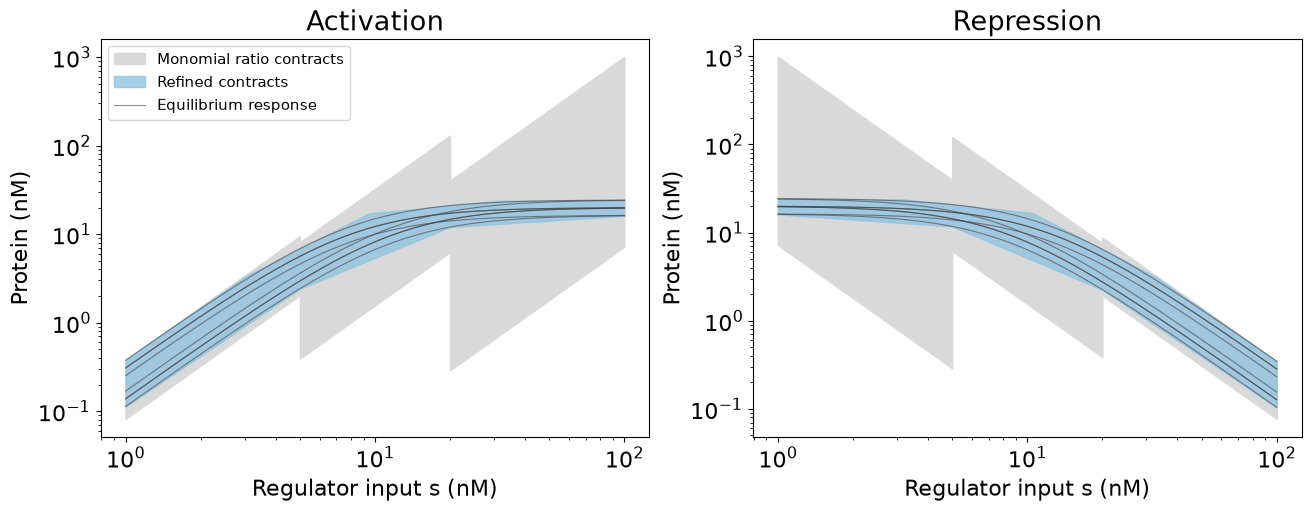

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5), layout="constrained")
for ax, positive in zip(axes, (True, False)):
    for index, (entry, other) in enumerate(
        zip(families[positive], reference[positive])
    ):
        s = np.geomspace(*entry["input_interval"], 100)
        lo, hi = hill_limits(other, s, dna)
        ax.fill_between(
            s,
            lo,
            hi,
            color="0.85",
            label="Monomial ratio contracts" if index == 0 else None,
        )
        lo, hi = hill_limits(entry, s, dna)
        ax.fill_between(
            s,
            lo,
            hi,
            color="#91c3df",
            alpha=0.8,
            label="Refined contracts" if index == 0 else None,
        )
    s = np.geomspace(1, 100, 250)
    for index, (k, K, delta) in enumerate(product(*bounds.values())):
        q = (s / K) ** n
        p = dna * k / delta * (q if positive else 1) / (1 + q)
        ax.plot(
            s,
            p,
            color="0.25",
            lw=0.8,
            alpha=0.6,
            label="Equilibrium response" if index == 0 else None,
        )
    ax.set(
        xscale="log",
        yscale="log",
        xlabel="Regulator input s (nM)",
        ylabel="Protein (nM)",
        title="Activation" if positive else "Repression",
    )
axes[0].legend(fontsize=11)
plt.show()

## Equilibrium guarantees

For the single protein activation example at $s=100$ nM and $d=2$ nM, abstraction refinement allows us to strengthen component guarantees under the same assumptions and certify the requirement $p^*\geq15$ nM.

In [4]:
point = interval("z_s", np.log(100), np.log(100)) + interval(
    "z_d", np.log(dna), np.log(dna)
)
for name, entry in [
    ("Monomial ratio", reference[True][2]),
    ("Refined", families[True][2]),
]:
    lower, upper = np.exp(to_contract(entry, point).get_variable_bounds("z_p"))
    print(f"{name}: {lower:.2f} <= p <= {upper:.2f} nM; p >= 15: {lower >= 15}")

Monomial ratio: 7.23 <= p <= 1011.03 nM; p >= 15: False
Refined: 16.13 <= p <= 24.29 nM; p >= 15: True


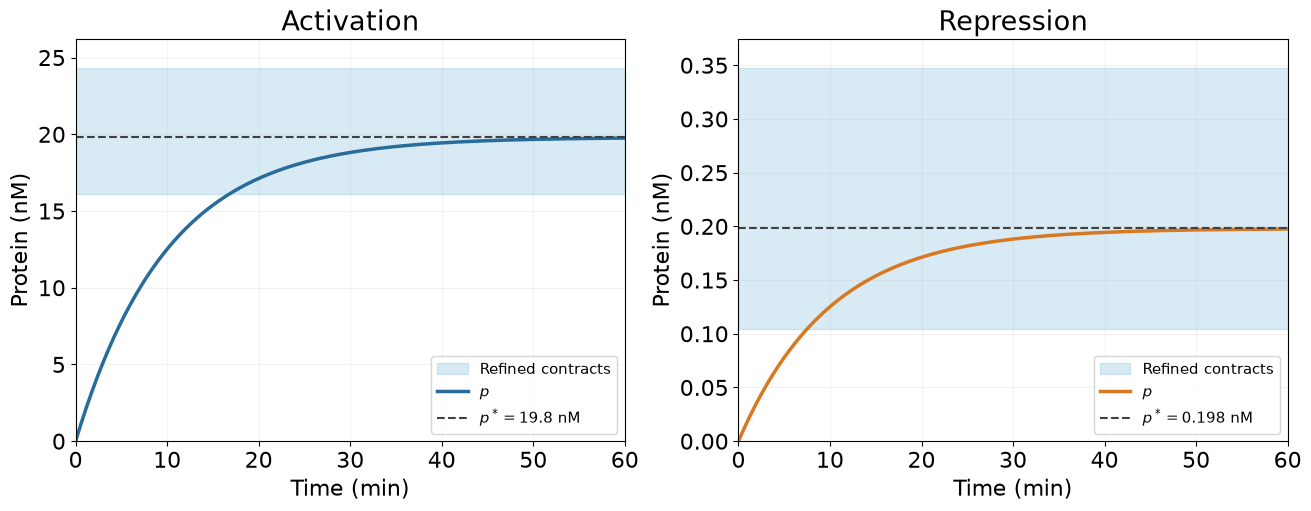

In [5]:
s = 100.0
nominal = {name: np.mean(values) for name, values in bounds.items()}
fig, axes = plt.subplots(1, 2, figsize=(13, 5), layout="constrained")
for ax, positive, color in zip(axes, (True, False), ("#286c99", "#d87820")):
    q = (s / nominal["K"]) ** n
    production = nominal["k"] * dna * (q if positive else 1) / (1 + q)
    equilibrium = production / nominal["delta"]
    lower, upper = hill_limits(families[positive][2], s, dna)
    solution = solve_ivp(
        lambda t, p: production - nominal["delta"] * p,
        (0, 150),
        [0.0],
        t_eval=np.linspace(0, 150, 500),
        rtol=1e-9,
        atol=1e-11,
    )
    assert solution.success
    assert lower <= equilibrium <= upper
    assert np.isclose(solution.y[0, -1], equilibrium, rtol=1e-6)
    ax.axhspan(lower, upper, color="#91c3df", alpha=0.35, label="Refined contracts")
    ax.plot(solution.t, solution.y[0], color=color, lw=2.5, label=r"$p$")
    ax.axhline(
        equilibrium, color="0.25", ls="--", lw=1.5,
        label=rf"$p^* = {equilibrium:.3g}$ nM",
    )
    ax.set(
        xlim=(0, 60),
        ylim=(0, 1.08 * upper),
        xlabel="Time (min)",
        ylabel="Protein (nM)",
        title="Activation" if positive else "Repression",
    )
    ax.legend(loc="lower right", fontsize=11)
    ax.grid(alpha=0.15)
plt.show()